
# Invoice Question Answering with Docling, RAG, Llama and Gradio

## Objective
Build an interactive application that accepts PDF invoices and answers questions about their contents.

## Pipeline
1. Upload a PDF invoice.
2. Extract document content using Docling.
3. Split the extracted content into meaningful chunks.
4. Generate embeddings using Sentence Transformers.
5. Store embeddings in a FAISS vector index.
6. Retrieve relevant chunks for a user's question.
7. Generate an answer using Llama 3.2 3B Instruct.
8. Display the answer and retrieved source information in Gradio.

## Technologies
- Docling: PDF extraction and OCR
- Sentence Transformers: Text embeddings
- FAISS: Vector similarity search
- Hugging Face Transformers: Llama inference
- Gradio: User interface


## Install dependencies

In [ ]:
%pip install -q docling sentence-transformers faiss-cpu gradio transformers accelerate

## Import libraries

In [ ]:
import re
import gc
import torch
import numpy as np
import faiss
import gradio as gr

from pathlib import Path
from docling.document_converter import DocumentConverter
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForCausalLM

## Load the models

In [ ]:
from huggingface_hub import notebook_login

notebook_login()

In [ ]:
# Embedding model
EMBEDDING_MODEL_ID = "sentence-transformers/all-MiniLM-L6-v2"

embedding_model = SentenceTransformer(EMBEDDING_MODEL_ID)

# Llama model
LLM_MODEL_ID = "meta-llama/Llama-3.2-3B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(LLM_MODEL_ID)

llm = AutoModelForCausalLM.from_pretrained(
    LLM_MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto"
)

llm.eval()

print("Embedding model loaded.")
print("Llama model loaded:", LLM_MODEL_ID)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

Embedding model loaded.
Llama model loaded: meta-llama/Llama-3.2-3B-Instruct
CUDA available: True
GPU: Tesla T4


## PDF Extraction using Docling

Initialize Docling to process an uploaded PDF. The extracted Markdown will be passed to the chunking function.


In [ ]:
converter = DocumentConverter()

def extract_invoice(pdf_path):
    """Extract an uploaded PDF invoice using Docling."""

    if not pdf_path:
        raise ValueError("Please upload a PDF invoice.")

    pdf_path = Path(pdf_path)

    if not pdf_path.exists():
        raise FileNotFoundError("The uploaded PDF could not be found.")

    if pdf_path.suffix.lower() != ".pdf":
        raise ValueError("Please upload a PDF file.")

    result = converter.convert(str(pdf_path))
    extracted_text = result.document.export_to_markdown()

    if not extracted_text.strip():
        raise ValueError("Docling did not extract any text from this PDF.")

    return extracted_text

print("Docling converter initialized.")

Docling converter initialized.


## Creating Invoice Chunking

This function processes the extracted Markdown rather than relying on any hard-coded invoice number or a specific file. It preserves table rows and separates totals and Terms and Conditions when those sections are identifiable.

In [ ]:

import re

def chunk_invoice(invoice_text, invoice_id, rows_per_chunk=5):
    """Chunk invoice header, product tables, totals, and T&C."""

    chunks = []

    def add_chunk(text, section):
        text = text.strip()
        if text:
            chunks.append({
                "invoice_id": invoice_id,
                "chunk_id": f"{invoice_id}_chunk_{len(chunks) + 1}",
                "section": section,
                "text": text
            })

    clean_text = re.sub(
        r"(?m)^Page \d+ of \d+\s*$",
        "",
        invoice_text
    ).strip()

    # Extract Markdown tables from the entire document first
    table_blocks = re.findall(
        r"(?m)(?:^\|.*\|\s*\n?)+",
        clean_text
    )

    text_without_tables = clean_text
    for table in table_blocks:
        text_without_tables = text_without_tables.replace(table, "", 1)

    # Extract T&C clauses wherever they occur in the document
    clauses = re.findall(
        r"(?m)^\s*\d+\.\s*.+$",
        text_without_tables
    )

    # Remove the T&C heading and clauses to isolate other invoice content
    non_tc_text = re.sub(
        r"(?im)^##\s*Terms and Conditions\s*$",
        "",
        text_without_tables
    )

    for clause in clauses:
        non_tc_text = non_tc_text.replace(clause, "", 1)

    # Extract subtotal, VAT, and total lines
    totals_lines = re.findall(
        r"(?im)^\s*(?:Subtotal\b.*|VAT\b.*|AED\s*[\d,]+(?:\.\d{2})?|Total\b.*)\s*$",
        non_tc_text
    )

    header_text = non_tc_text
    for line in totals_lines:
        header_text = re.sub(
            re.escape(line), "", header_text, count=1, flags=re.I
        )

    add_chunk(header_text, "invoice_header")

    # Chunk product tables
    for table_number, table in enumerate(table_blocks, start=1):
        lines = [line.strip() for line in table.splitlines() if line.strip()]
        lines = [
            line for line in lines
            if not re.fullmatch(r"\|[\s|:-]+\|", line)
        ]

        if len(lines) < 2:
            continue

        table_header = lines[0]
        data_rows = lines[1:]

        for start in range(0, len(data_rows), rows_per_chunk):
            row_group = data_rows[start:start + rows_per_chunk]
            add_chunk(
                "\n".join([table_header] + row_group),
                f"line_items_table_{table_number}"
            )

    # Chunk totals separately
    if totals_lines:
        add_chunk("\n".join(totals_lines), "invoice_totals")

    # Chunk T&C clauses separately
    for clause in clauses:
        add_chunk(clause, "terms_and_conditions")

    if not chunks and clean_text:
        add_chunk(clean_text, "invoice_content")

    return chunks


print("Chunking function is ready.")

Chunking function is ready.


## Build the vector index
Each uploaded invoice will receive its own FAISS index. That way, a new invoice replaces the currently active invoice rather than mixing its information with previous uploads.

In [ ]:
def build_vector_index(chunks):
    """Generate embeddings and build a FAISS index for one invoice."""

    if not chunks:
        raise ValueError("No chunks available to index.")

    texts = [chunk["text"] for chunk in chunks]

    embeddings = embedding_model.encode(
        texts,
        convert_to_numpy=True,
        normalize_embeddings=True,
        show_progress_bar=False
    ).astype("float32")

    index = faiss.IndexFlatIP(embeddings.shape[1])
    index.add(embeddings)

    return index, embeddings

print("Vector indexing function ready.")

Vector indexing function ready.


## Retrieve relevant context

In [ ]:

import re

def retrieve_context(question, chunks, index, top_k=3):
    question_lower = question.lower()

    # 1. Identify questions about invoice header information
    header_keywords = [
        "invoice number", "invoice no", "invoice id",
        "invoice date", "date of invoice",
        "supplier", "vendor", "bill to", "billed to",
        "currency", "invoice details"
    ]

    # 2. Prioritize matching SKU chunks for product lookups
    sku_match = re.search(r"\b[A-Z]{2,}-[A-Z]+-\d+\b", question, re.I)

    selected = []
    selected_ids = set()

    def add_chunk(chunk):
        chunk_id = chunk.get("chunk_id")
        if chunk_id not in selected_ids:
            selected.append(chunk)
            selected_ids.add(chunk_id)

    # For invoice header questions, add header chunks first
    if any(keyword in question_lower for keyword in header_keywords):
        for chunk in chunks:
            if chunk.get("section") in [
                "invoice_header", "invoice_content"
            ]:
                add_chunk(chunk)

    # For exact SKU questions, prioritize chunks containing that SKU
    if sku_match:
        sku = sku_match.group(0).lower()
        for chunk in chunks:
            if sku in chunk.get("text", "").lower():
                add_chunk(chunk)

    # 3. Fill remaining slots with FAISS results
    if len(selected) < top_k:
        query_embedding = embedding_model.encode(
            [question],
            normalize_embeddings=True
        )

        scores, indices = index.search(
            query_embedding.astype("float32"),
            min(len(chunks), top_k + len(selected))
        )

        for idx in indices[0]:
            if idx < 0:
                continue

            add_chunk(chunks[int(idx)])

            if len(selected) >= top_k:
                break

    return selected[:max(top_k, len([
        c for c in chunks
        if any(k in question_lower for k in header_keywords)
        and c.get("section") in ["invoice_header", "invoice_content"]
    ]))]

## Generate an answer using Llama

In [ ]:
def generate_answer(question, chunks, index, top_k=3):
    """Generate an invoice answer using retrieved context."""

    retrieved = retrieve_context(
        question,
        chunks,
        index,
        top_k=top_k
    )

    context = "\n\n".join(
        f"[Section: {item['section']}]\n{item['text']}"
        for item in retrieved
    )

    messages = [
        {
            "role": "system",
            "content": (
                "You are an invoice question-answering assistant. "
                "Answer using only the supplied invoice context. "
                "Do not invent missing details. If the answer is absent, "
                "say it could not be found in the extracted invoice. "
                "Preserve all material conditions, percentages and time "
                "periods. Use the currency stated in the invoice. "
                "Never substitute USD or $ for AED. "
                "For a product question, report the exact SKU's quantity, "
                "unit price and line total when present."
            )
        },
        {
            "role": "user",
            "content": (
                f"Invoice context:\n{context}\n\n"
                f"Question: {question}\n\n"
                "Answer directly and concisely."
            )
        }
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        clean_up_tokenization_spaces=False
    ).to(llm.device)

    with torch.no_grad():
        outputs = llm.generate(
            **inputs,
            max_new_tokens=180,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    generated_tokens = outputs[0][inputs["input_ids"].shape[1]:]

    answer = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    ).strip()

    sources = "\n\n".join(
        f"**{item['section']}** — {item['chunk_id']}\n{item['text']}"
        for item in retrieved
    )

    return answer, sources

print("Answer-generation function ready.")

Answer-generation function ready.


## Build the Gradio interface

In [ ]:
app_state = {
    "chunks": None,
    "index": None,
    "invoice_id": None,
    "filename": None
}

print("Invoice app state initialized.")

Invoice app state initialized.


In [ ]:
import uuid
from pathlib import Path

def process_pdf(pdf_path):
    try:
        if not pdf_path:
            return "Please upload a PDF invoice.", ""

        pdf_path = Path(pdf_path)

        # Step 1: Extract invoice text using Docling
        extracted_text = extract_invoice(pdf_path)

        # Step 2: Create invoice chunks
        invoice_id = f"{pdf_path.stem}_{uuid.uuid4().hex[:8]}"
        chunks = chunk_invoice(extracted_text, invoice_id)

        if not chunks:
            return "No chunks were created.", extracted_text

        # Step 3: Generate embeddings and build FAISS index
        index, embeddings = build_vector_index(chunks)

        # Step 4: Save the processed invoice
        app_state.update({
            "chunks": chunks,
            "index": index,
            "invoice_id": invoice_id,
            "filename": pdf_path.name
        })

        status = (
            f"Successfully processed: {pdf_path.name}\n"
            f"Chunks created: {len(chunks)}\n"
            f"Embeddings created: {len(embeddings)}"
        )

        return status, extracted_text

    except Exception as exc:
        return f"Processing failed: {exc}", ""

print("PDF-processing function ready.")

PDF-processing function ready.


In [ ]:
def chat_with_invoice(message, history):
    history = list(history or [])

    if not message or not message.strip():
        return history, "", "Please enter a question."

    if (
        not app_state.get("chunks")
        or app_state.get("index") is None
    ):
        answer = "Please upload and process an invoice first."
        sources = ""

    else:
        try:
            question = message.strip()
            query = question.lower()

            # Detect requests for an invoice summary
            summary_phrases = [
                "summarize this invoice",
                "summarise this invoice",
                "summary of this invoice",
                "summarize the invoice",
                "summarise the invoice",
                "give me an invoice summary",
                "give me a summary of the invoice",
                "provide an invoice summary",
                "overview of this invoice",
                "summarize this bill",
                "summarise this bill"
            ]

            is_summary = any(
                phrase in query for phrase in summary_phrases
            )

            # Detect requests for all terms and conditions
            asks_all_terms = (
                ("term" in query or "condition" in query)
                and any(word in query for word in [
                    "what are", "list", "all", "show",
                    "tell me", "explain", "summarize",
                    "summarise"
                ])
            )

            if is_summary:
                # Use all extracted chunks to create a complete summary
                selected_chunks = app_state["chunks"]

                context = "\n\n".join(
                    f"[Section: {chunk['section']}]\n{chunk['text']}"
                    for chunk in selected_chunks
                )

                system_prompt = (
                    "You are an invoice summarization assistant. "
                    "Summarize only information present in the supplied "
                    "extracted invoice. Organize the answer using these "
                    "headings where information is available: "
                    "Invoice Details, Financial Summary, Products, "
                    "Important Terms and Conditions, and Contact Details. "
                    "Include the invoice number, date, supplier, billed-to "
                    "party, and currency when available. Include subtotal, "
                    "tax or VAT, and grand total when available. "
                    "Summarize product quantities and prices when the "
                    "extracted data supports them. List important payment, "
                    "delivery, return, dispute, and legal conditions. "
                    "Preserve all amounts, currencies, percentages, and "
                    "time periods exactly. Do not invent missing details. "
                    "If a value is unclear or absent, say it was not "
                    "clearly available in the extracted invoice. "
                    "Do not claim that the invoice is paid or unpaid "
                    "unless the supplied text explicitly says so."
                )

                user_prompt = (
                    f"Extracted invoice content:\n{context}\n\n"
                    f"User request: {question}\n\n"
                    "Provide a clear, concise, structured summary. "
                    "Do not omit important information present in the text."
                )

                messages = [
                    {
                        "role": "system",
                        "content": system_prompt
                    },
                    {
                        "role": "user",
                        "content": user_prompt
                    }
                ]

                prompt = tokenizer.apply_chat_template(
                    messages,
                    tokenize=False,
                    add_generation_prompt=True
                )

                inputs = tokenizer(
                    prompt,
                    return_tensors="pt"
                ).to(llm.device)

                with torch.no_grad():
                    outputs = llm.generate(
                        **inputs,
                        max_new_tokens=600,
                        do_sample=False,
                        pad_token_id=tokenizer.eos_token_id
                    )

                generated_tokens = outputs[0][
                    inputs["input_ids"].shape[1]:
                ]

                answer = tokenizer.decode(
                    generated_tokens,
                    skip_special_tokens=True
                ).strip()

                # Show every chunk used for the summary
                sources = "\n\n".join(
                    f"**{chunk['section']}** — "
                    f"{chunk['chunk_id']}\n{chunk['text']}"
                    for chunk in selected_chunks
                )

            elif asks_all_terms:
                # Retrieve all T&C chunks, not just top_k=3
                selected_chunks = [
                    chunk for chunk in app_state["chunks"]
                    if chunk["section"] == "terms_and_conditions"
                ]

                if not selected_chunks:
                    answer = (
                        "No terms and conditions were found in the "
                        "extracted invoice."
                    )
                    sources = ""

                else:
                    context = "\n\n".join(
                        chunk["text"] for chunk in selected_chunks
                    )

                    messages = [
                        {
                            "role": "system",
                            "content": (
                                "Answer using only the supplied invoice "
                                "text. List every provided term and "
                                "condition. Preserve the original meaning, "
                                "percentages, deadlines, and restrictions. "
                                "Do not invent information."
                            )
                        },
                        {
                            "role": "user",
                            "content": (
                                f"Invoice terms and conditions:\n{context}\n\n"
                                f"Question: {question}\n\n"
                                "List all terms and conditions as a numbered list."
                            )
                        }
                    ]

                    prompt = tokenizer.apply_chat_template(
                        messages,
                        tokenize=False,
                        add_generation_prompt=True
                    )

                    inputs = tokenizer(
                        prompt,
                        return_tensors="pt"
                    ).to(llm.device)

                    with torch.no_grad():
                        outputs = llm.generate(
                            **inputs,
                            max_new_tokens=400,
                            do_sample=False,
                            pad_token_id=tokenizer.eos_token_id
                        )

                    generated_tokens = outputs[0][
                        inputs["input_ids"].shape[1]:
                    ]

                    answer = tokenizer.decode(
                        generated_tokens,
                        skip_special_tokens=True
                    ).strip()

                    sources = "\n\n".join(
                        f"**{chunk['section']}** — "
                        f"{chunk['chunk_id']}\n{chunk['text']}"
                        for chunk in selected_chunks
                    )

            else:
                # Normal RAG retrieval for individual questions
                answer, sources = generate_answer(
                    question,
                    app_state["chunks"],
                    app_state["index"],
                    top_k=3
                )

        except Exception as exc:
            answer = f"An error occurred: {exc}"
            sources = ""

    # Preserve the previous conversation
    history.append({
        "role": "user",
        "content": message.strip()
    })

    history.append({
        "role": "assistant",
        "content": answer
    })

    return history, "", sources


print("Chat function updated with invoice summarization.")

Chat function updated with invoice summarization.


In [ ]:
with gr.Blocks(title="Invoice RAG Assistant") as demo:

    gr.Markdown("# Invoice RAG Assistant")
    gr.Markdown(
        "Upload a PDF invoice, process it, and ask questions. "
        "Your previous questions and answers will remain visible."
    )

    # 1. Upload and process invoice
    gr.Markdown("Upload Invoice")

    with gr.Row():
        pdf_input = gr.File(
            label="Upload Invoice PDF",
            file_types=[".pdf"],
            type="filepath"
        )

        process_button = gr.Button(
            "Process Invoice",
            variant="primary"
        )

    status_output = gr.Textbox(
        label="Processing Status",
        interactive=False
    )

    extracted_output = gr.Textbox(
        label="Extracted Invoice Text",
        lines=8,
        interactive=False
    )

    process_button.click(
        fn=process_pdf,
        inputs=[pdf_input],
        outputs=[status_output, extracted_output]
    )

    # 2. Chat interface
    gr.Markdown("## Chat with Your Invoice")

    chatbot = gr.Chatbot(
        label="Invoice Conversation",
        height=450,
        layout="bubble"
    )

    question_input = gr.Textbox(
        label="Your Question",
        placeholder="e.g. What is the total amount including VAT?",
        lines=2
    )

    with gr.Row():
        send_button = gr.Button(
            "Send",
            variant="primary"
        )

        clear_button = gr.Button("Clear Chat")

    # Display sources for the latest answer
    sources_output = gr.Markdown(
        "Sources for the latest answer will appear here."
    )

    # 3. Connect Send button to the previously defined chat function
    send_button.click(
        fn=chat_with_invoice,
        inputs=[question_input, chatbot],
        outputs=[chatbot, question_input, sources_output]
    )

    # 4. Press Enter to send the question
    question_input.submit(
        fn=chat_with_invoice,
        inputs=[question_input, chatbot],
        outputs=[chatbot, question_input, sources_output]
    )

    # 5. Clear conversation without removing the processed invoice
    def clear_chat():
        return (
            [],
            "",
            "Sources for the latest answer will appear here."
        )

    clear_button.click(
        fn=clear_chat,
        inputs=[],
        outputs=[chatbot, question_input, sources_output]
    )

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


2026/10/28 10:01:07 [W] [service.go:132] login to server failed: dial tcp 44.237.78.176:7000: connect: connection refused


<IPython.core.display.Javascript object>

Loading weights:   0%|          | 0/770 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/conv.py:548: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /pytorch/aten/src/ATen/native/Convolution.cpp:1024.)
  return F.conv2d(
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


## Invoice 1

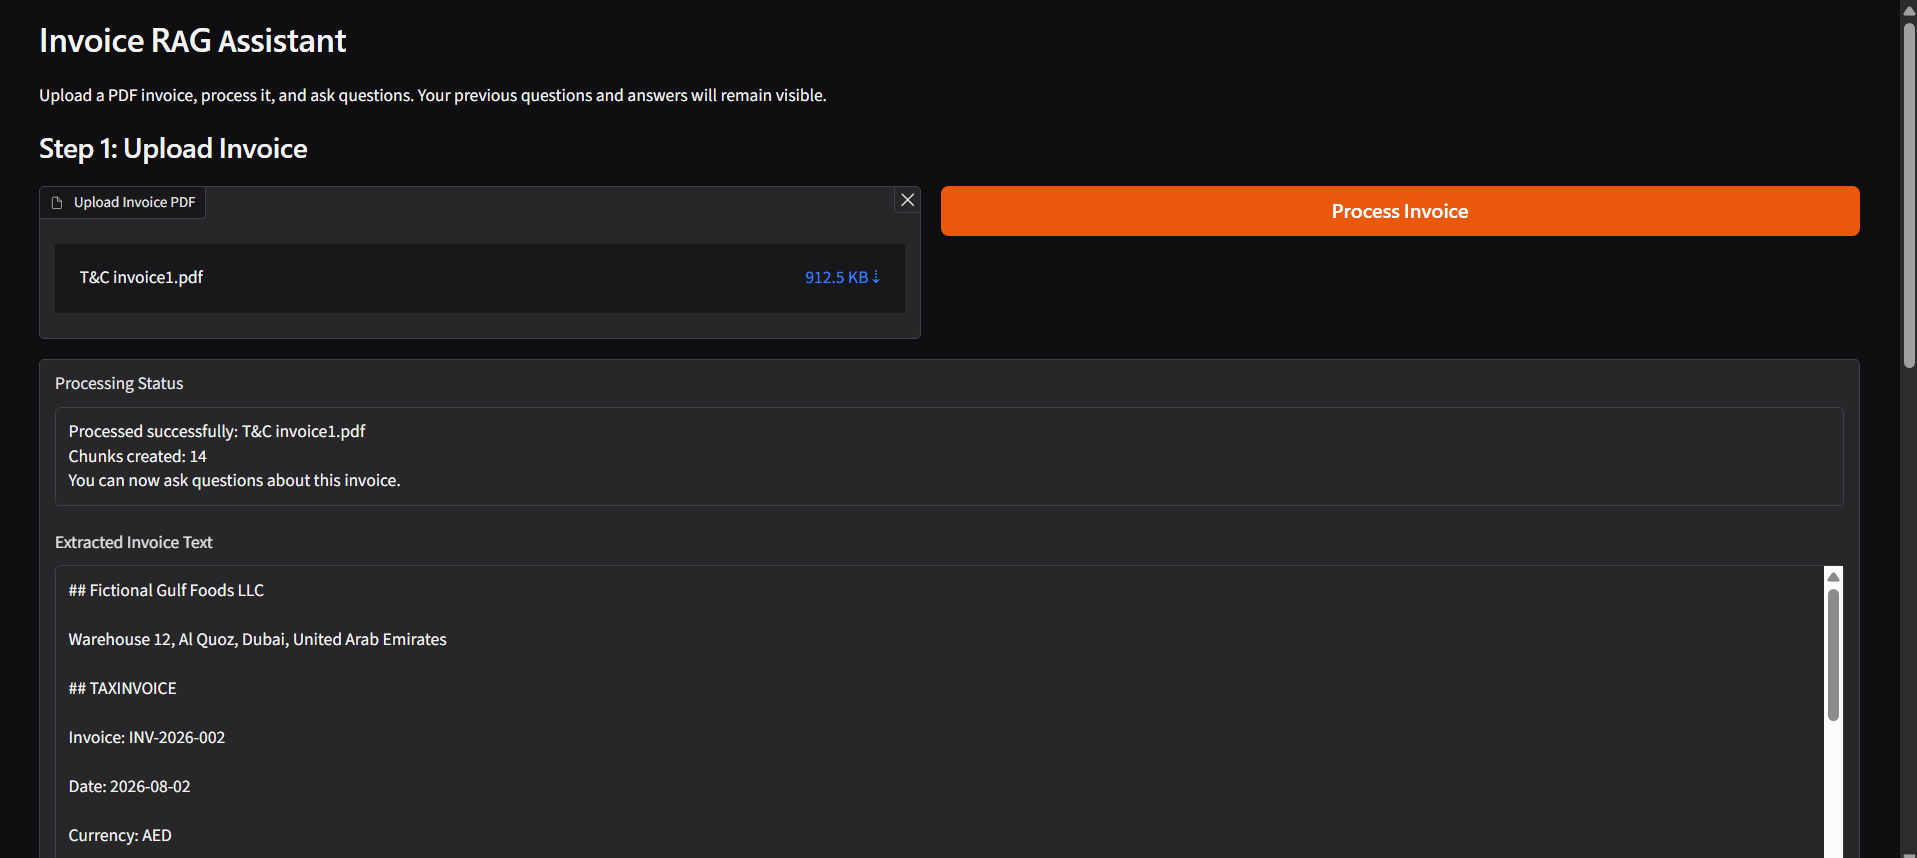

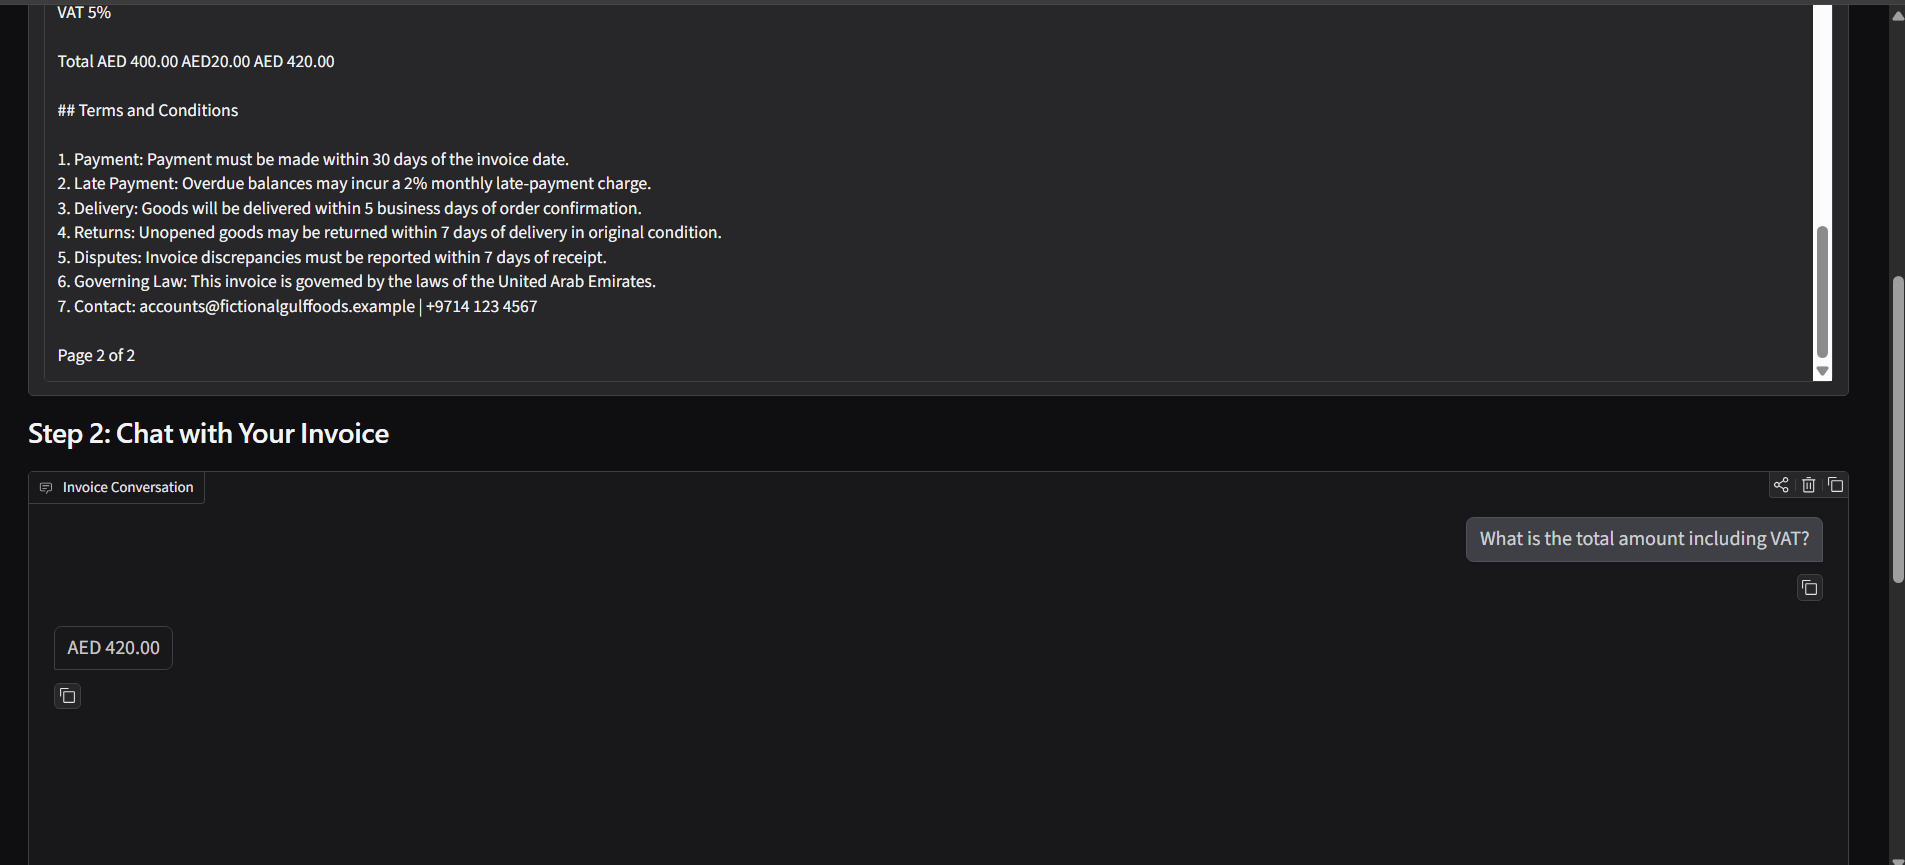

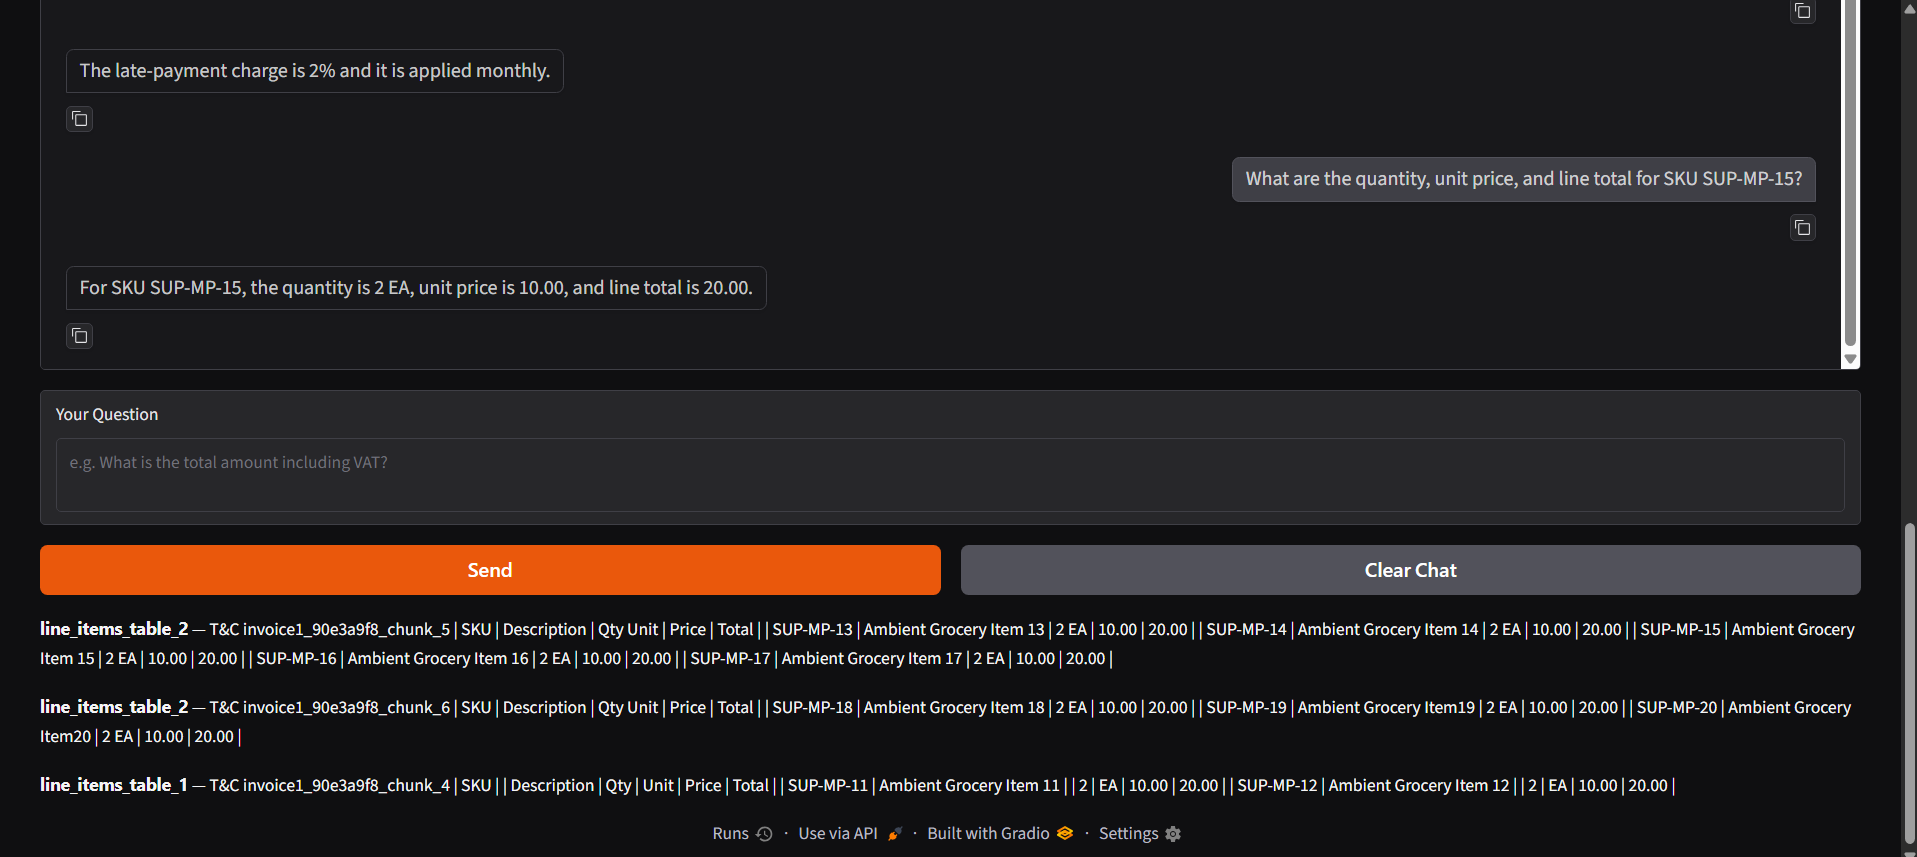

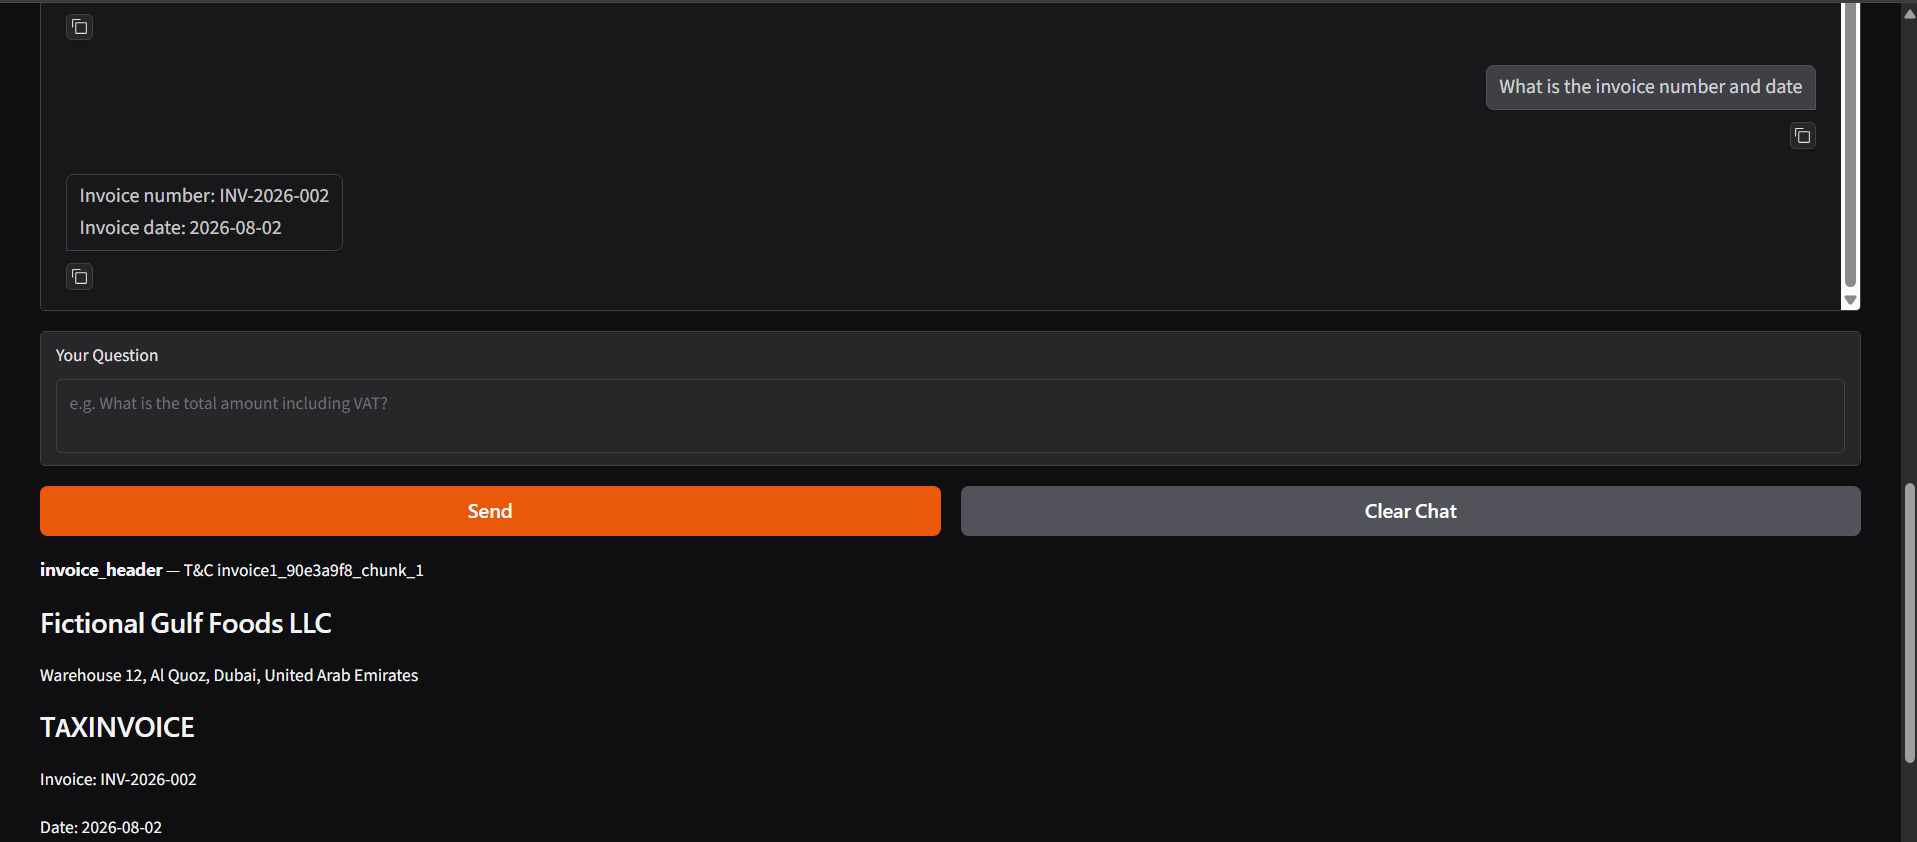

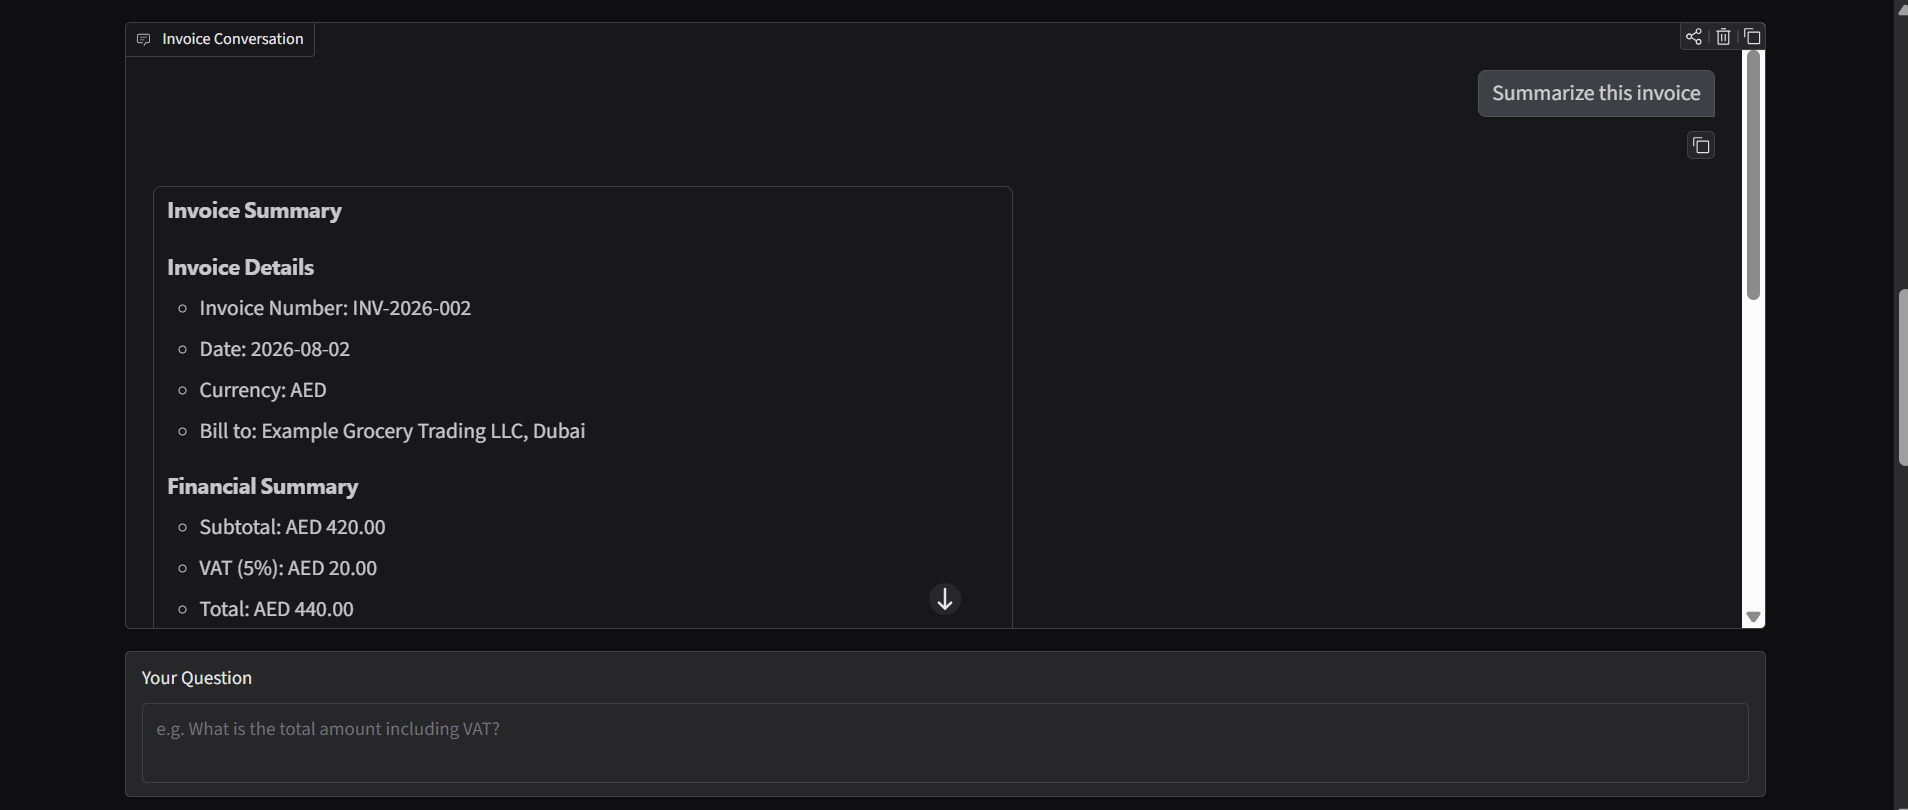

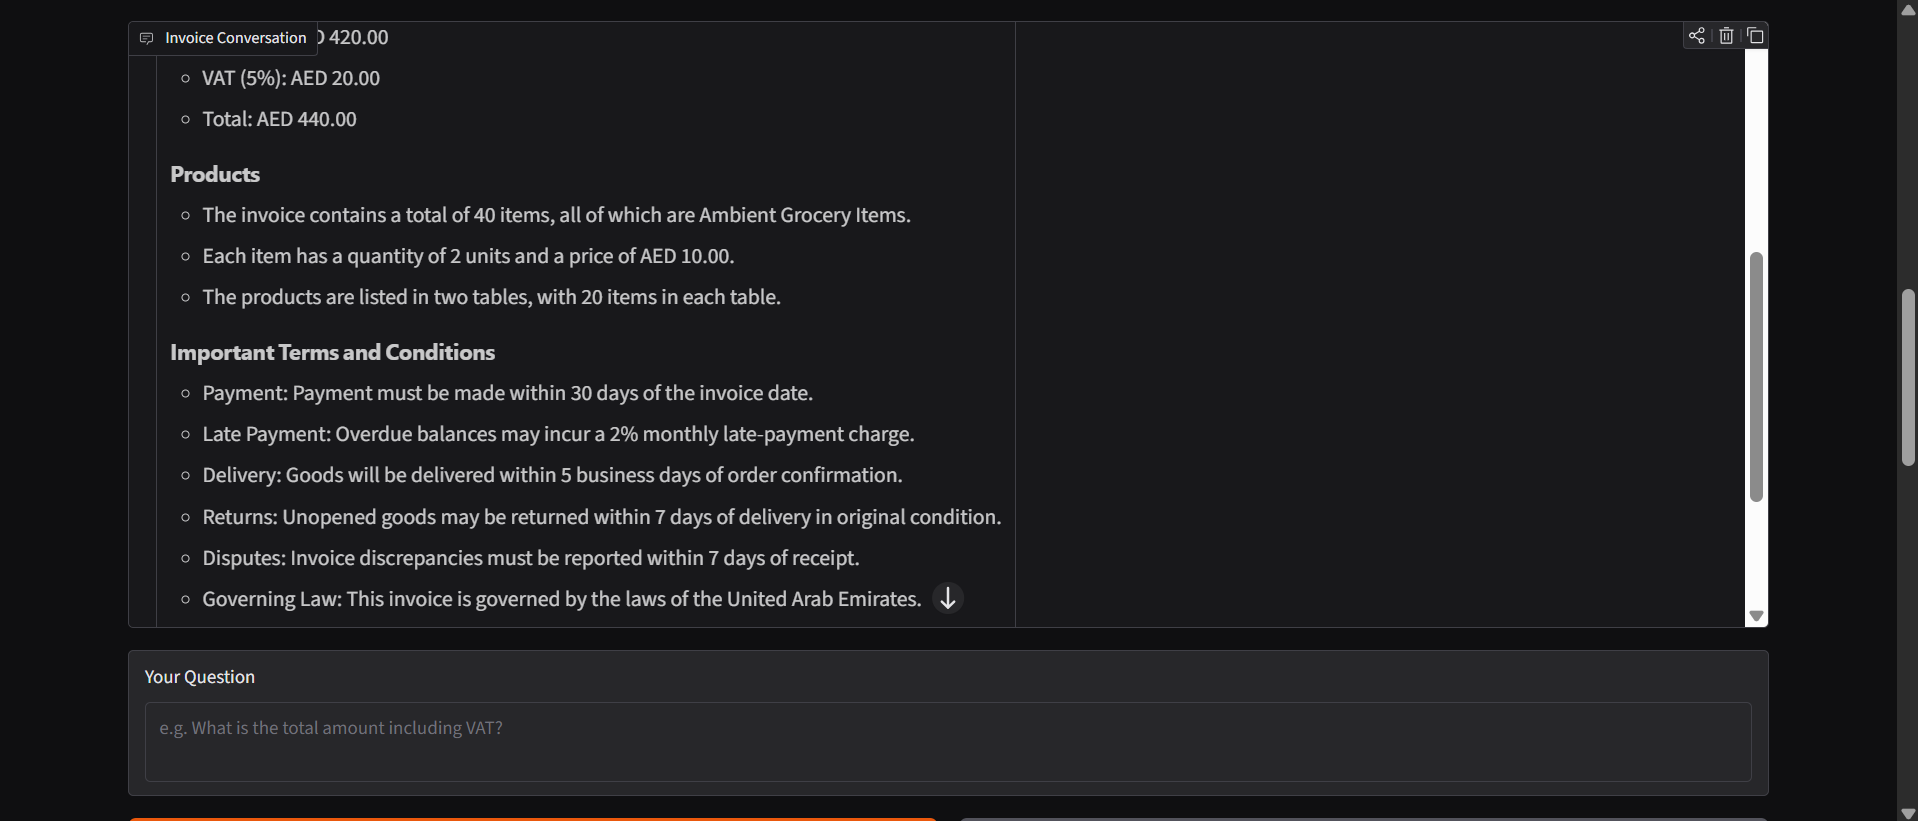

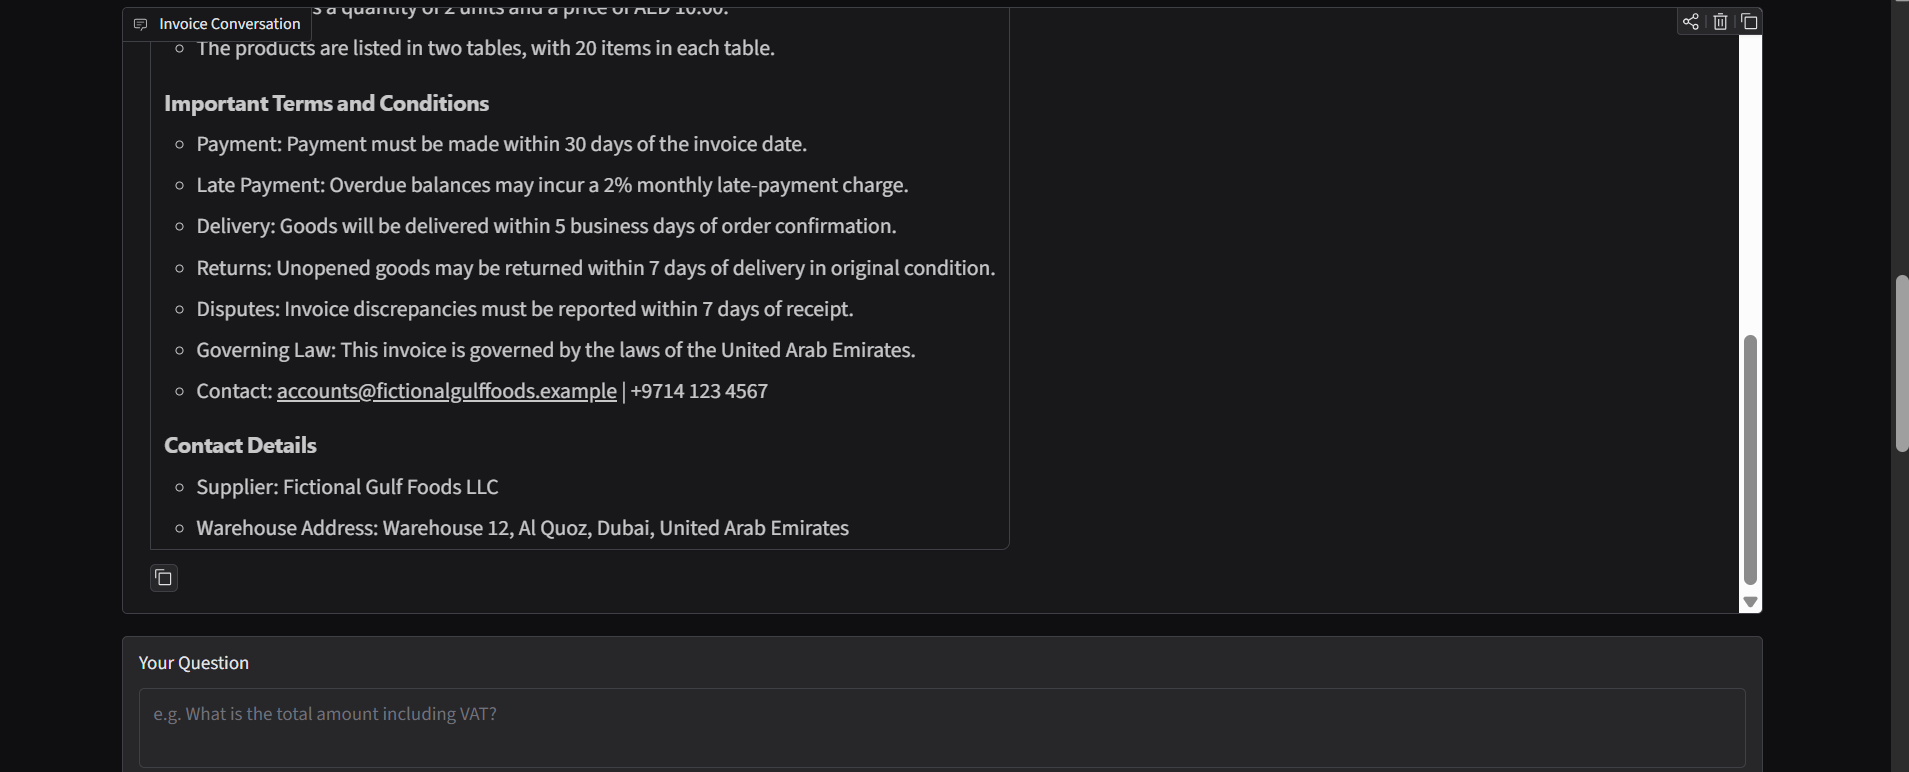

## Invoice 2

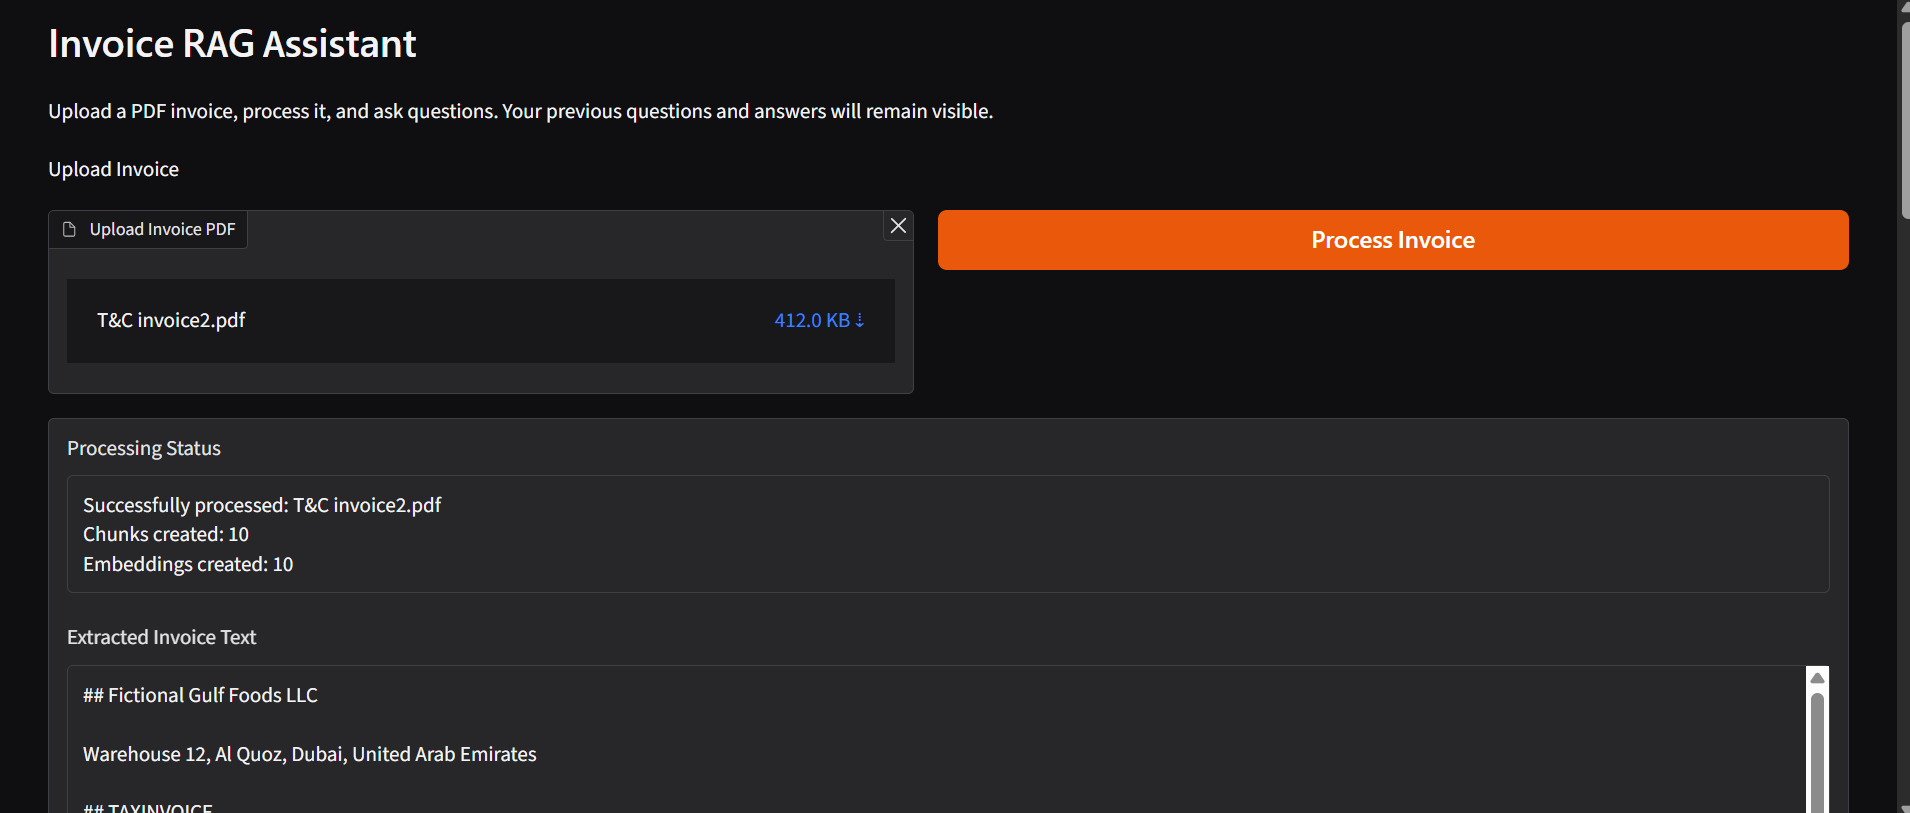

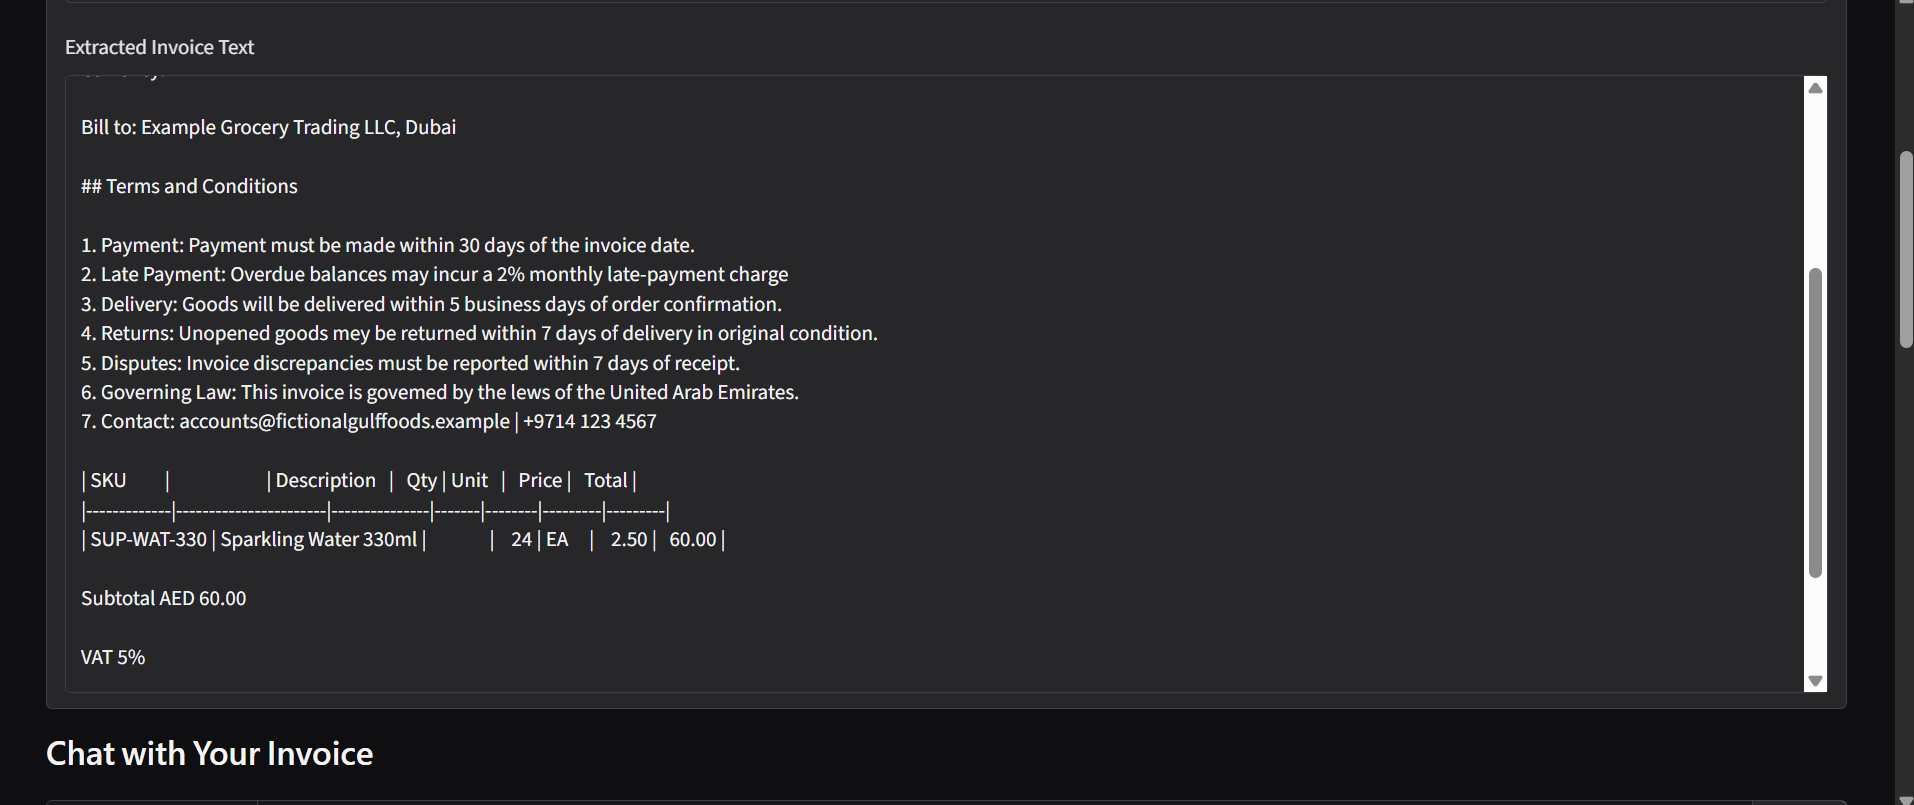

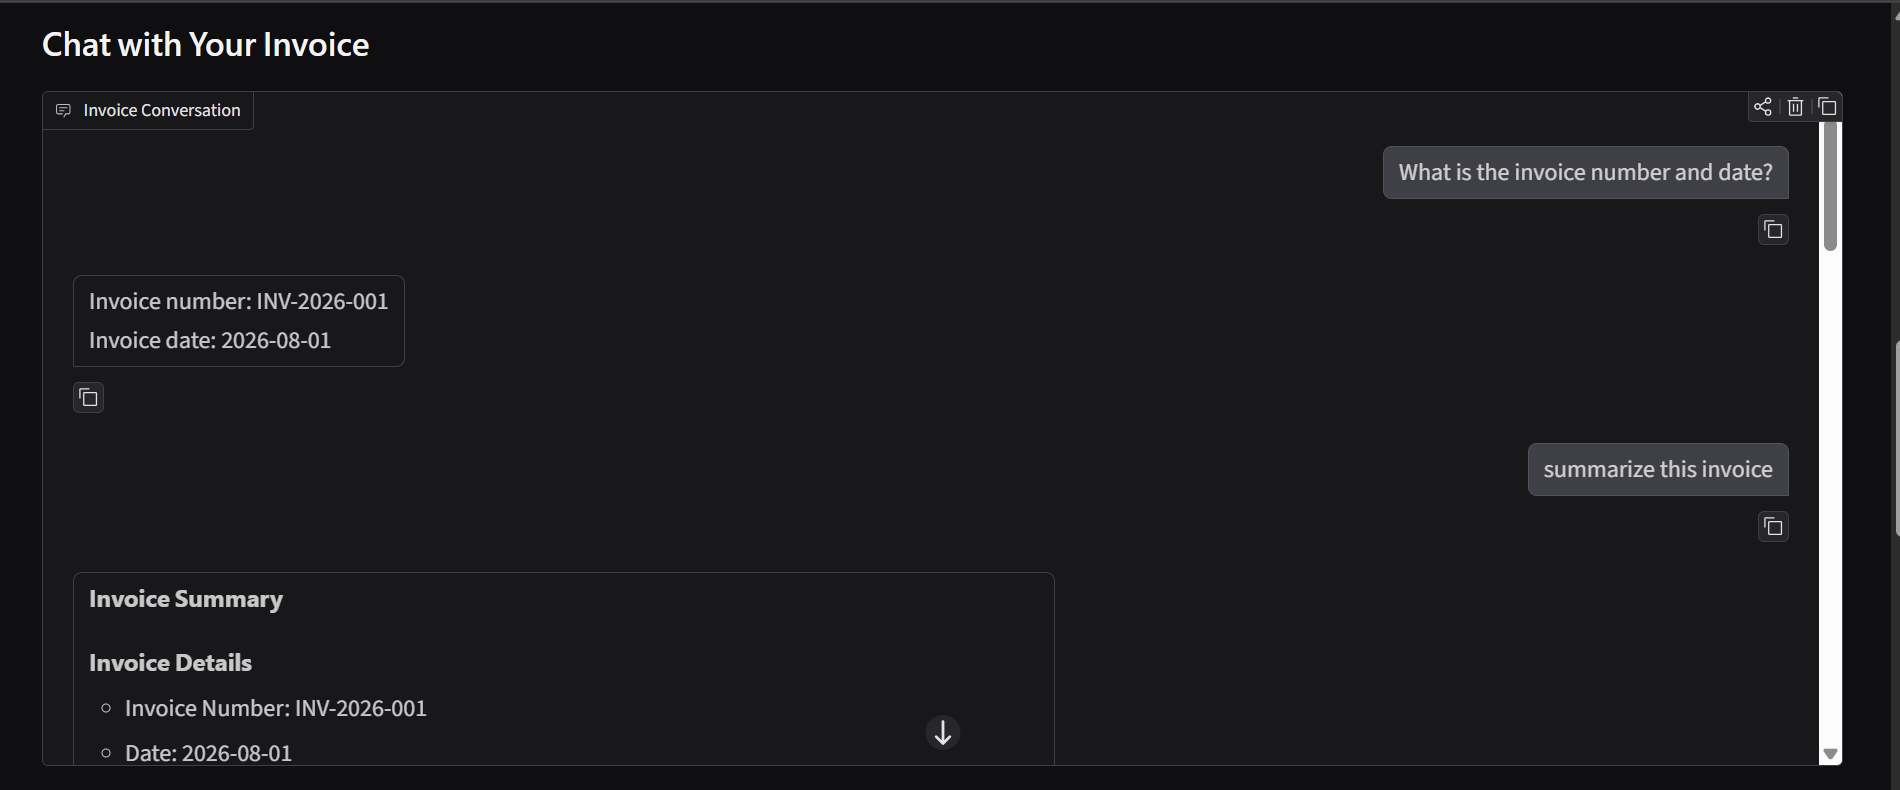

**Invoice Summary**

**Invoice Details**

* Invoice Number: INV-2026-001
* Date: 2026-08-01
* Supplier: Fictional Gulf Foods LLC
* Billed-to Party: Example Grocery Trading LLC, Dubai
* Currency: AED

**Financial Summary**

* Subtotal: AED 60.00
* VAT (5%): AED 3.00
* Total: AED 63.00

**Products**

| SKU | Description | Quantity | Unit | Price | Total |
| --- | --- | --- | --- | --- | --- |
| SUP-WAT-330 | Sparkling Water 330ml | 24 | EA | AED 2.50 | AED 60.00 |

**Important Terms and Conditions**

1. Payment: Payment must be made within 30 days of the invoice date.
2. Late Payment: Overdue balances may incur a 2% monthly late-payment charge.
3. Delivery: Goods will be delivered within 5 business days of order confirmation.
4. Returns: Unopened goods may be returned within 7 days of delivery in original condition.
5. Disputes: Invoice discrepancies must be reported within 7 days of receipt.
6. Governing Law: This invoice is governed by the laws of the United Arab Emirates.
7. Contact: accounts@fictionalgulffoods.example | +9714 123 4567

**Contact Details**

* Supplier: Fictional Gulf Foods LLC
* Warehouse Address: Warehouse 12, Al Quoz, Dubai, United Arab Emirates
* Billed-to Party: Example Grocery Trading LLC, Dubai

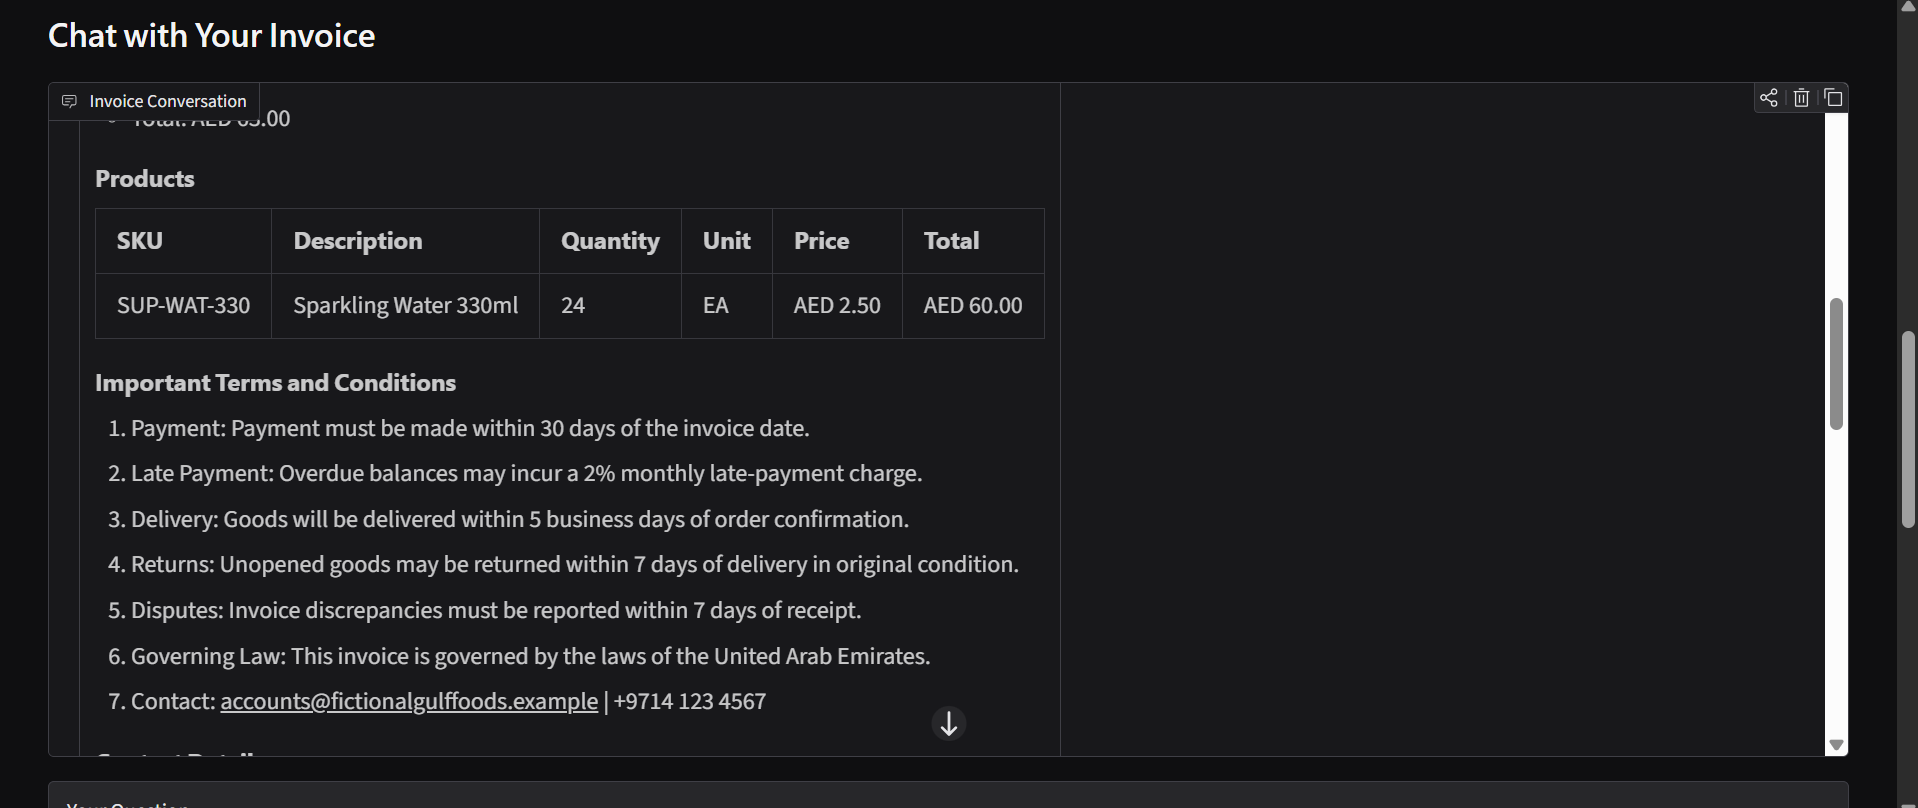

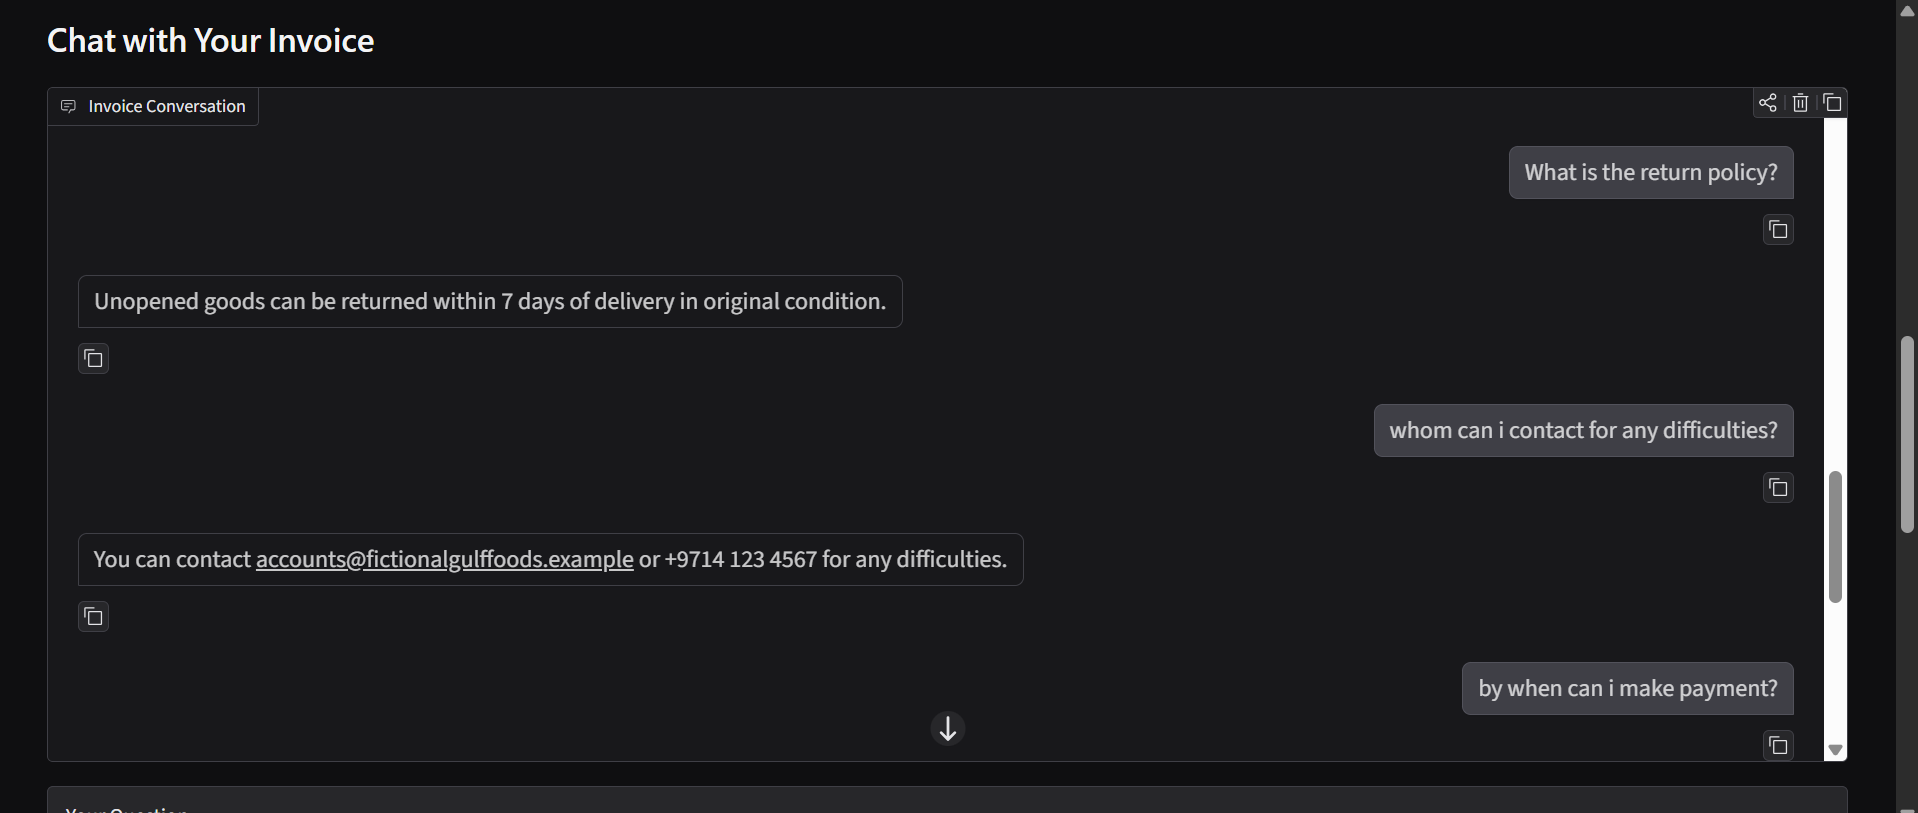

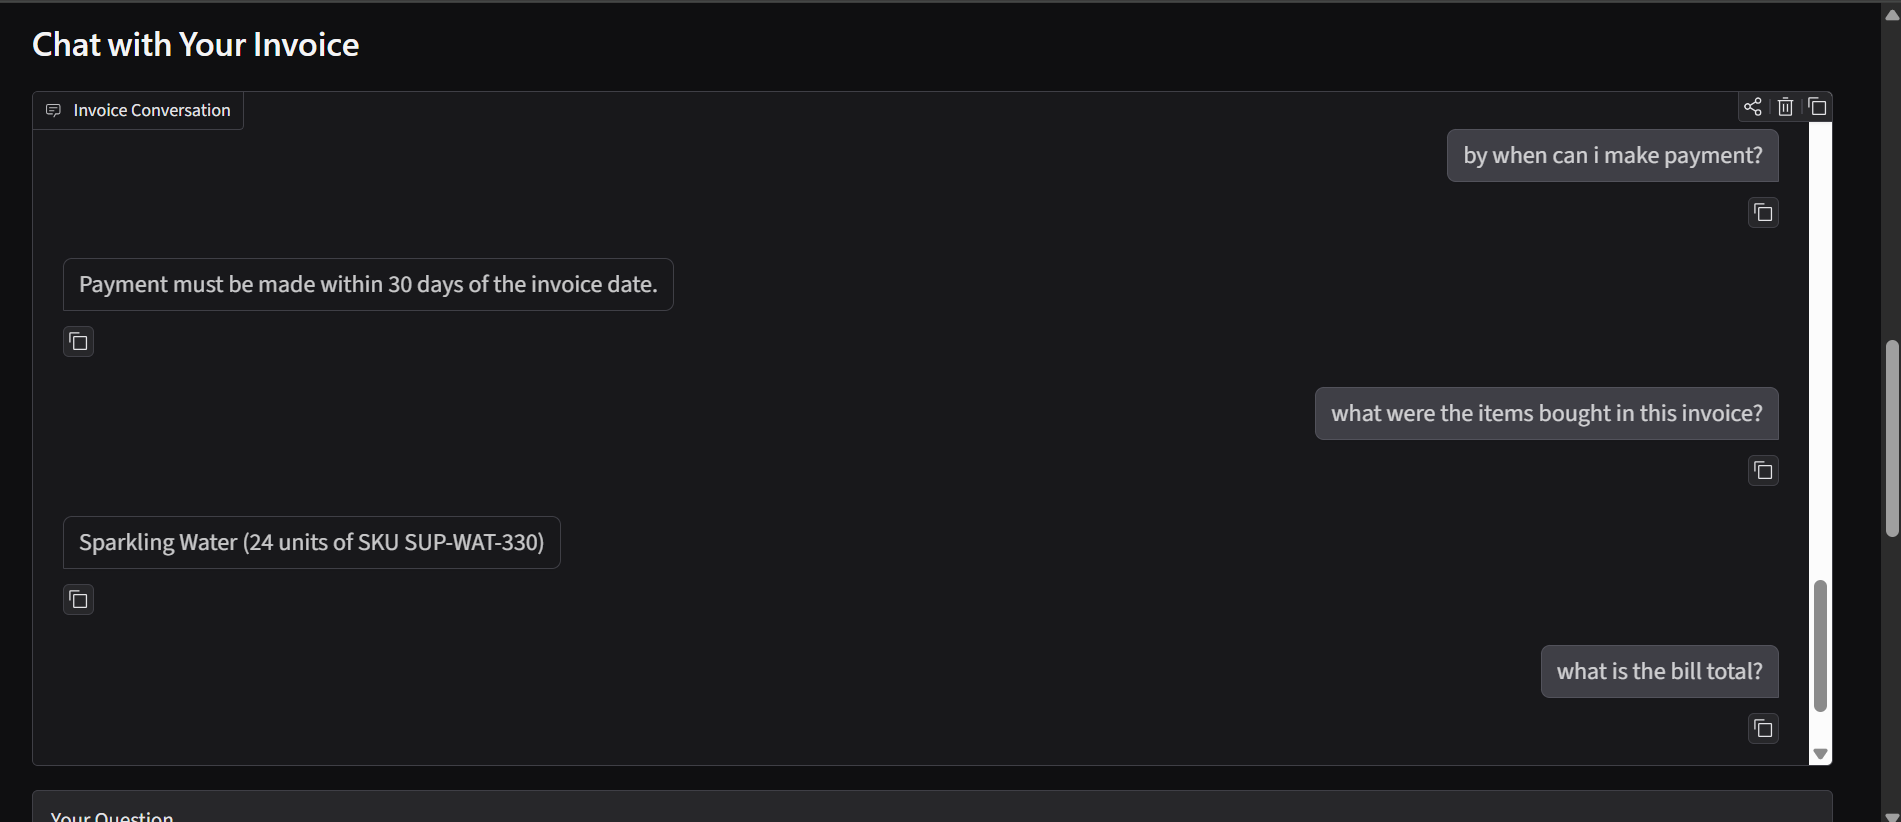

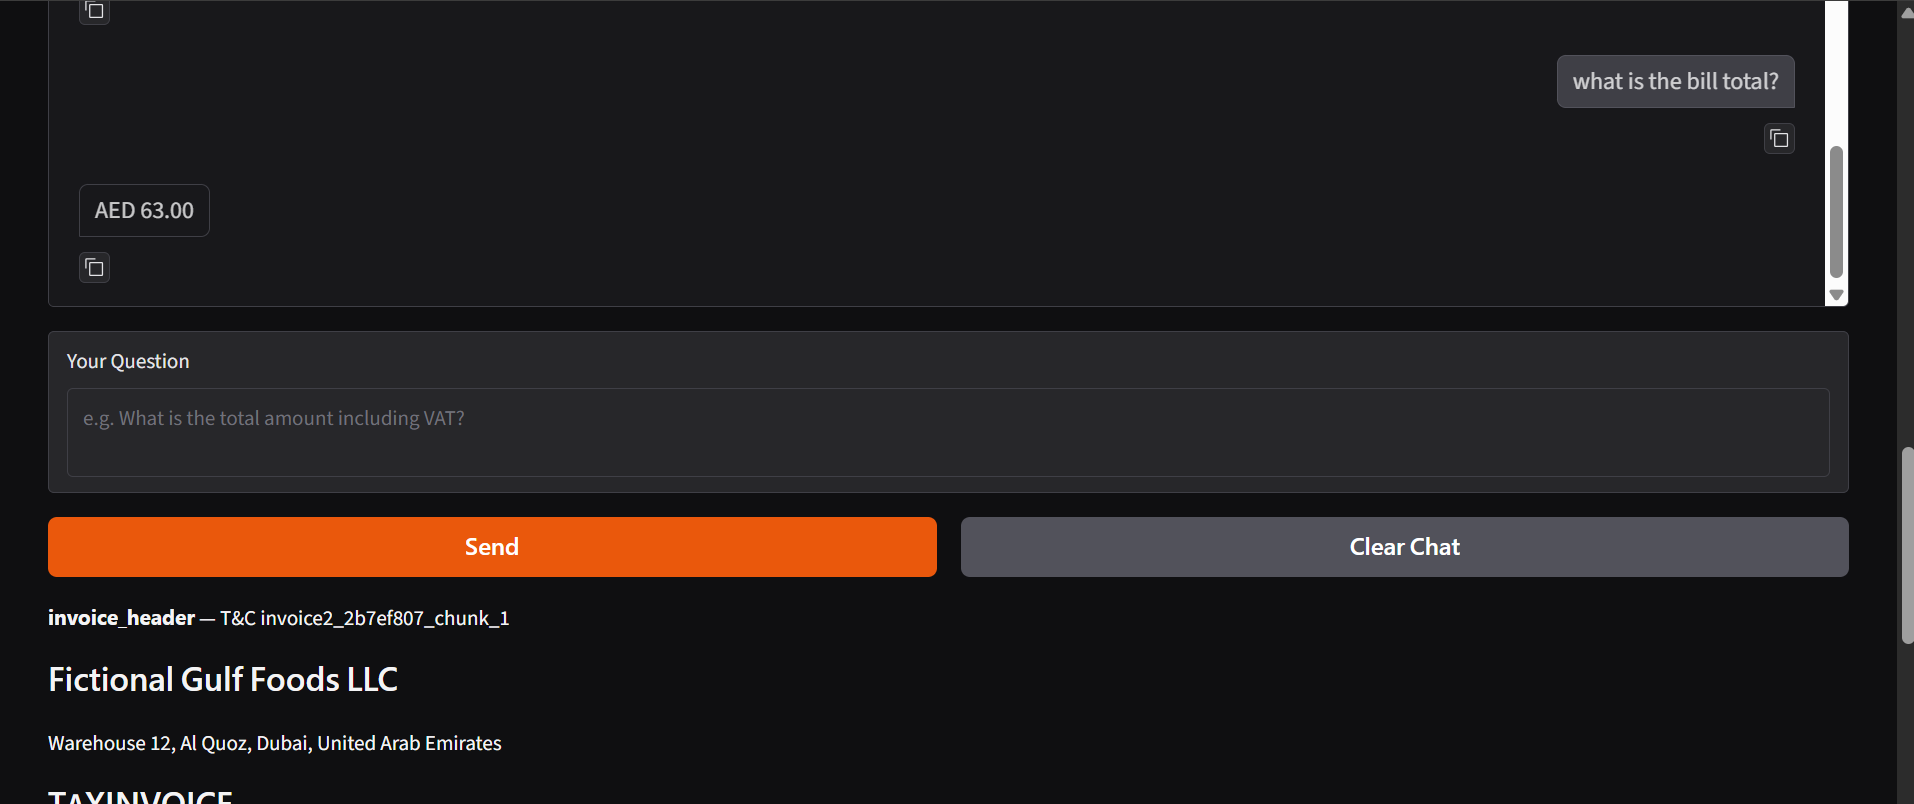